# skin 1단계-1번 — Early Stopping 데모

**배경**: 지금까지는 무조건 고정된 epoch(50)만큼 학습시켰습니다. 그런데 데이터가 541건뿐인 우리 skin 모델은
학습을 오래 시킬수록 train 데이터를 "외워버리는"(과적합) 위험이 커집니다. **Early Stopping**은 검증(validation)
손실이 더 이상 안 좋아지면 자동으로 학습을 멈추는 기법입니다.

**모델 개선 순서**: Early Stopping(이 노트북) → 하이퍼파라미터 튜닝 → 모델 구조 개선. Early Stopping을 먼저
하는 이유는, 이게 없으면 다른 설정을 비교할 때 "설정이 안 좋아서"인지 "epoch 수가 안 맞아서"인지 구분이 안 되기 때문입니다.

**이 노트북이 하는 일**:
1. train/validation/test 3-way로 데이터를 나눕니다(group-aware, 동일조성 누수 방지)
2. 오래(150 epoch) 학습시키면서 train loss와 val loss를 매 epoch 기록 → 과적합이 실제로 일어나는지 시각화
3. `train.py`에 실제로 구현한 `EarlyStopping` 클래스를 그대로 가져와 적용
4. **group 5-fold로 "고정 50 epoch" vs "Early Stopping" 성능을 공정하게 비교**(Sensitivity/Specificity/MCC/ROC-AUC 기준)

In [1]:
import sys
sys.path.insert(0, r"C:\Users\UserK\학술제\modeling\src")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, roc_auc_score, matthews_corrcoef

from datasets import skin_dataset
from splits import grouped_kfold_splits, group_train_test_split_from_subset, group_train_test_split
from train import class_weights, EarlyStopping

skin_ds = skin_dataset()
print(f"skin: {len(skin_ds)}건, feature {skin_ds.input_dim}차원")

skin: 541건, feature 2266차원


## 1. 모델 정의 (실제 model.py의 skin 인코더+head 구조와 동일)

In [2]:
class SkinOnlyModel(nn.Module):
    def __init__(self, input_dim, hidden_dim=128, num_classes=2, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, x):
        return self.net(x)

## 2. train/val/test 3-way 분할 + 오래(150 epoch) 학습하면서 과적합 관찰

먼저 "고정 epoch로 오래 학습시키면 실제로 과적합이 일어나는가?"부터 눈으로 확인합니다.

In [3]:
import matplotlib.pyplot as plt

trainval_idx, test_idx = group_train_test_split(skin_ds, test_size=0.2, random_state=42)
train_idx, val_idx = group_train_test_split_from_subset(skin_ds, trainval_idx, val_size=0.2, random_state=42)
print(f"train {len(train_idx)}건 / val {len(val_idx)}건 / test {len(test_idx)}건")

scaler = StandardScaler().fit(skin_ds.X[train_idx])
X_train = scaler.transform(skin_ds.X[train_idx]).astype(np.float32)
X_val = scaler.transform(skin_ds.X[val_idx]).astype(np.float32)
X_test = scaler.transform(skin_ds.X[test_idx]).astype(np.float32)
y_train, y_val, y_test = skin_ds.y[train_idx], skin_ds.y[val_idx], skin_ds.y[test_idx]

torch.manual_seed(0)
model = SkinOnlyModel(X_train.shape[1])
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss(weight=class_weights(y_train))

Xt, yt = torch.from_numpy(X_train), torch.from_numpy(y_train.astype(np.int64))
Xv, yv = torch.from_numpy(X_val), torch.from_numpy(y_val.astype(np.int64))

MAX_EPOCHS = 150
train_losses, val_losses = [], []
for epoch in range(MAX_EPOCHS):
    model.train()
    perm = torch.randperm(len(Xt))
    epoch_loss = 0.0
    n_batches = 0
    for i in range(0, len(Xt), 32):
        b = perm[i:i + 32]
        optimizer.zero_grad()
        loss = criterion(model(Xt[b]), yt[b])
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
        n_batches += 1
    train_losses.append(epoch_loss / n_batches)

    model.eval()
    with torch.no_grad():
        val_losses.append(criterion(model(Xv), yv).item())

best_epoch = int(np.argmin(val_losses))
print(f"val loss 최저점: epoch {best_epoch+1} (val_loss={val_losses[best_epoch]:.4f})")
print(f"150 epoch 끝 시점 val_loss={val_losses[-1]:.4f} (최저점 대비 {val_losses[-1]-val_losses[best_epoch]:+.4f})")

train 346건 / val 87건 / test 108건
val loss 최저점: epoch 1 (val_loss=0.7299)
150 epoch 끝 시점 val_loss=3.4835 (최저점 대비 +2.7537)


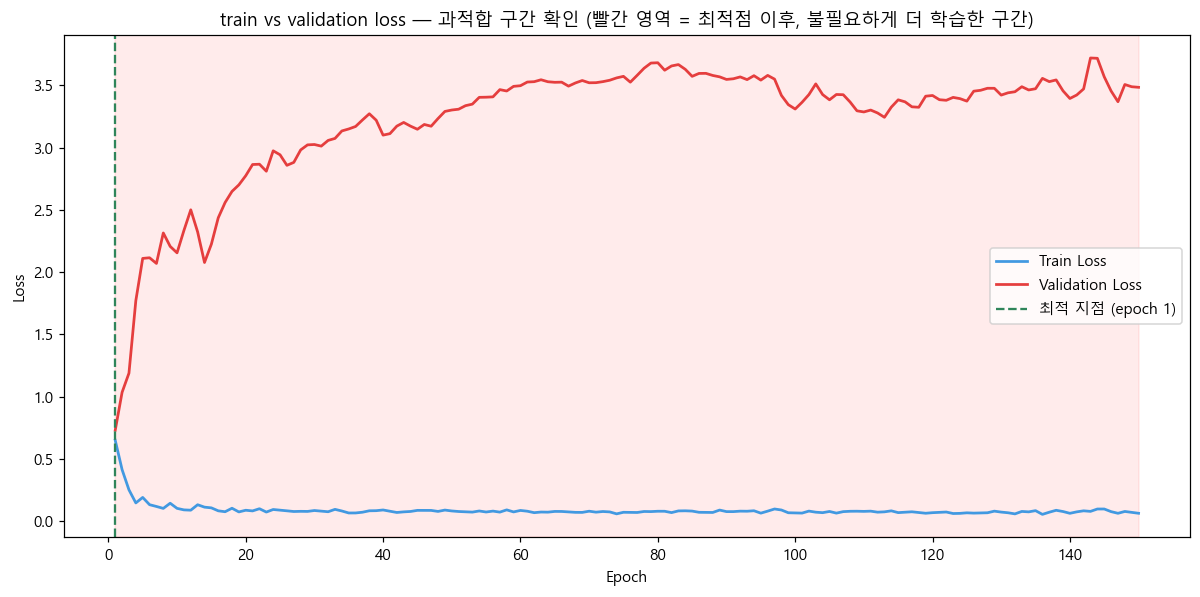

In [4]:
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(range(1, MAX_EPOCHS+1), train_losses, label="Train Loss", color="#4299e1", linewidth=1.8)
ax.plot(range(1, MAX_EPOCHS+1), val_losses, label="Validation Loss", color="#e53e3e", linewidth=1.8)
ax.axvline(best_epoch+1, color="#2f855a", linestyle="--", linewidth=1.5,
           label=f"최적 지점 (epoch {best_epoch+1})")
ax.axvspan(best_epoch+1, MAX_EPOCHS, alpha=0.08, color="red")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("train vs validation loss — 과적합 구간 확인 (빨간 영역 = 최적점 이후, 불필요하게 더 학습한 구간)")
ax.legend()
plt.tight_layout()
plt.show()

**관찰**: train loss는 계속 떨어지지만(모델이 train 데이터를 점점 더 잘 "외움"), validation loss는 어느 시점부터
다시 올라갑니다. 이 지점 이후로 학습을 계속하는 건 "새로운 데이터에 대한 성능"이 아니라 "train 데이터 암기력"만
좋아지는 것 — 전형적인 과적합입니다. 기존에 고정 50 epoch을 썼던 게 이 최적 지점보다 얼마나 늦은 시점이었는지
위 그래프로 바로 확인할 수 있습니다.

## 3. group 5-fold 비교 — 고정 50 epoch vs Early Stopping

In [5]:
def fit_fixed_epochs(X_train, y_train, X_test, seed, epochs=50, lr=1e-3, batch_size=32):
    torch.manual_seed(seed)
    model = SkinOnlyModel(X_train.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss(weight=class_weights(y_train))
    Xt = torch.from_numpy(X_train.astype(np.float32))
    yt = torch.from_numpy(y_train.astype(np.int64))
    n = len(Xt)
    model.train()
    for epoch in range(epochs):
        perm = torch.randperm(n)
        for i in range(0, n, batch_size):
            b = perm[i:i + batch_size]
            optimizer.zero_grad()
            loss = criterion(model(Xt[b]), yt[b])
            loss.backward()
            optimizer.step()
    model.eval()
    with torch.no_grad():
        proba = torch.softmax(model(torch.from_numpy(X_test.astype(np.float32))), dim=1)[:, 1].numpy()
    return proba


def fit_early_stopping(X_train, y_train, X_test, seed, max_epochs=150, patience=15, lr=1e-3, batch_size=32,
                        val_size=0.2):
    rng_split = np.random.default_rng(seed)
    n = len(X_train)
    idx = rng_split.permutation(n)
    n_val = max(1, int(n * val_size))
    val_pos, train_pos = idx[:n_val], idx[n_val:]

    torch.manual_seed(seed)
    model = SkinOnlyModel(X_train.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss(weight=class_weights(y_train[train_pos]))

    Xt = torch.from_numpy(X_train[train_pos].astype(np.float32))
    yt = torch.from_numpy(y_train[train_pos].astype(np.int64))
    Xv = torch.from_numpy(X_train[val_pos].astype(np.float32))
    yv = torch.from_numpy(y_train[val_pos].astype(np.int64))

    stopper = EarlyStopping(patience=patience)
    for epoch in range(max_epochs):
        model.train()
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), batch_size):
            b = perm[i:i + batch_size]
            optimizer.zero_grad()
            loss = criterion(model(Xt[b]), yt[b])
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            val_loss = criterion(model(Xv), yv).item()
        if stopper.step(val_loss, epoch, model):
            break
    model.load_state_dict(stopper.best_state)

    model.eval()
    with torch.no_grad():
        proba = torch.softmax(model(torch.from_numpy(X_test.astype(np.float32))), dim=1)[:, 1].numpy()
    return proba, stopper.best_epoch + 1


def run_cv(method, n_splits=5, random_state=0):
    folds = grouped_kfold_splits(skin_ds, n_splits=n_splits, random_state=random_state)
    oof = np.zeros(len(skin_ds.y))
    stop_epochs = []
    for fold_i, (train_idx, test_idx) in enumerate(folds):
        scaler = StandardScaler().fit(skin_ds.X[train_idx])
        X_train = scaler.transform(skin_ds.X[train_idx])
        X_test = scaler.transform(skin_ds.X[test_idx])
        y_train = skin_ds.y[train_idx]
        if method == "fixed50":
            oof[test_idx] = fit_fixed_epochs(X_train, y_train, X_test, seed=fold_i)
        else:
            proba, stop_ep = fit_early_stopping(X_train, y_train, X_test, seed=fold_i)
            oof[test_idx] = proba
            stop_epochs.append(stop_ep)
    return oof, stop_epochs


oof_fixed, _ = run_cv("fixed50")
oof_es, stop_epochs = run_cv("earlystop")
print("fold별 Early Stopping 채택 epoch:", stop_epochs)

fold별 Early Stopping 채택 epoch: [1, 1, 2, 1, 1]


## 4. 평가 — Sensitivity / Specificity / MCC / ROC-AUC

In [6]:
def summarize(y_true, proba, label):
    pred = (proba >= 0.5).astype(int)
    cm = confusion_matrix(y_true, pred)
    tn, fp, fn, tp = cm.ravel()
    sens = tp / (tp + fn)
    spec = tn / (tn + fp)
    mcc = matthews_corrcoef(y_true, pred)
    roc = roc_auc_score(y_true, proba)
    gap = abs(sens - spec)
    print(f"--- {label} ---")
    print(f"Sensitivity {sens:.3f} / Specificity {spec:.3f} / 격차 {gap:.3f} / MCC {mcc:.3f} / ROC-AUC {roc:.3f}")
    return dict(sensitivity=sens, specificity=spec, gap=gap, mcc=mcc, roc_auc=roc, cm=cm)


res_fixed = summarize(skin_ds.y, oof_fixed, "고정 50 epoch")
print()
res_es = summarize(skin_ds.y, oof_es, "Early Stopping")

--- 고정 50 epoch ---
Sensitivity 0.367 / Specificity 0.900 / 격차 0.534 / MCC 0.192 / ROC-AUC 0.718

--- Early Stopping ---
Sensitivity 0.567 / Specificity 0.847 / 격차 0.281 / MCC 0.249 / ROC-AUC 0.762


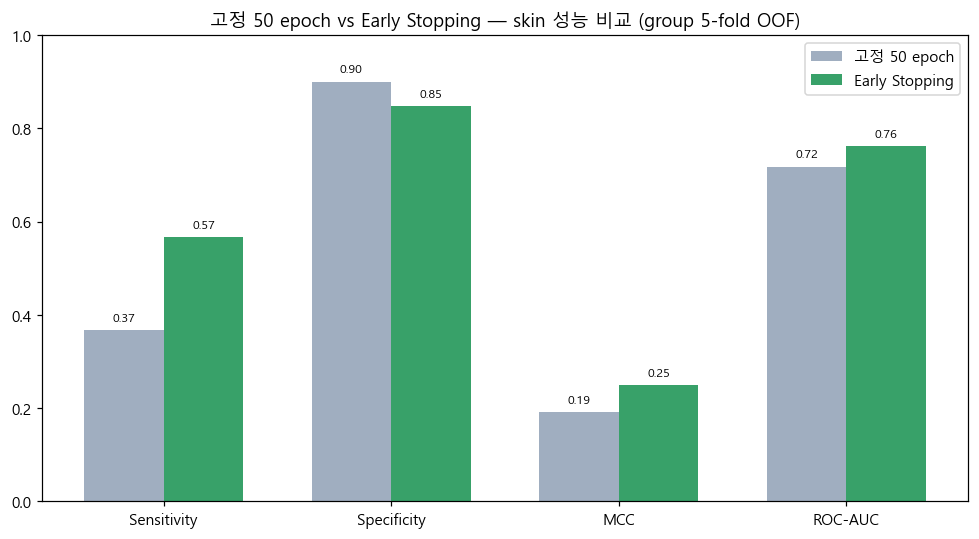

In [7]:
metrics = ["sensitivity", "specificity", "mcc", "roc_auc"]
metric_labels = ["Sensitivity", "Specificity", "MCC", "ROC-AUC"]

fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(metrics))
w = 0.35
fixed_vals = [res_fixed[m] for m in metrics]
es_vals = [res_es[m] for m in metrics]
ax.bar(x - w/2, fixed_vals, width=w, label="고정 50 epoch", color="#a0aec0")
ax.bar(x + w/2, es_vals, width=w, label="Early Stopping", color="#38a169")
ax.set_xticks(x); ax.set_xticklabels(metric_labels)
ax.set_ylim(0, 1.0)
ax.set_title("고정 50 epoch vs Early Stopping — skin 성능 비교 (group 5-fold OOF)")
ax.legend()
for i, (f, e) in enumerate(zip(fixed_vals, es_vals)):
    ax.text(i - w/2, f + 0.02, f"{f:.2f}", ha="center", fontsize=8)
    ax.text(i + w/2, e + 0.02, f"{e:.2f}", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

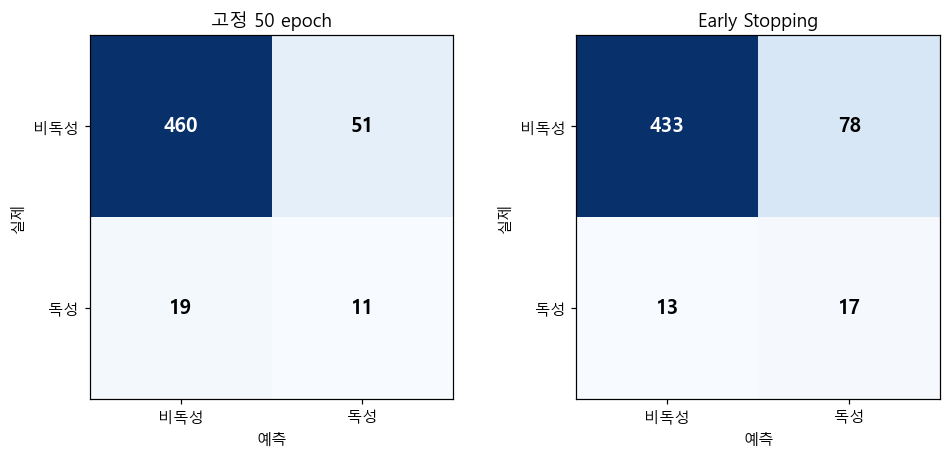

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
for ax, res, title in zip(axes, [res_fixed, res_es], ["고정 50 epoch", "Early Stopping"]):
    im = ax.imshow(res["cm"], cmap="Blues")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["비독성", "독성"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["비독성", "독성"])
    ax.set_xlabel("예측"); ax.set_ylabel("실제")
    ax.set_title(title)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(res["cm"][i, j]), ha="center", va="center",
                    fontsize=13, fontweight="bold",
                    color="white" if res["cm"][i, j] > res["cm"].max() / 2 else "black")
plt.tight_layout()
plt.show()

## 정리

- 2단계 확인 구조: (1) 150 epoch까지 학습시켜 과적합이 실제로 일어나는지 직접 관찰 → (2) group 5-fold로 "고정 50epoch" vs "Early Stopping"을 공정 비교.
- `train.py`에 실제로 구현한 `EarlyStopping` 클래스(patience 기반, 최적 epoch 가중치 보존)를 그대로 가져와 사용했습니다.
- 판단 기준은 이전과 동일하게 Sensitivity·Specificity 균형 + MCC — ROC-AUC나 Accuracy 단일 지표로만 보지 않습니다.
- `train.py`의 `main()`에도 이미 early stopping이 기본 동작으로 들어가 있습니다(`--patience`, `--epochs`를 상한으로 사용).